# Chapter 4: What does each mistake cost? The 1-in-N test

*Choosing the metric from business cost; the 1-in-N test (course construction) · also searched as: cost-sensitive evaluation, choosing a metric, expected cost threshold*

**Who needs the answer.** Anand Iyer, Finance controller at Kalpa Retail, who has priced the two mistakes: a wasted nudge costs Rs 40 and a repeater left alone costs about Rs 1,200 of margin. Marketing wants to nudge widely and Finance wants to nudge nobody it is unsure of; the prices settle it.

**The questions on the way.** How many wasted nudges does one found buyer pay for? How sure must the model be before a nudge pays? Which metric leads when a miss costs thirty times a false alarm? Does the same rule work for a fraud block and a loan?

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

COST_WASTED, COST_MISSED = 40, 1200          # Anand's prices: a wasted nudge, a missed repeater
print(f"one repeater's margin pays for {COST_MISSED // COST_WASTED} wasted nudges: {COST_MISSED // COST_WASTED} x Rs {COST_WASTED} = Rs {COST_MISSED:,}")

one repeater's margin pays for 30 wasted nudges: 30 x Rs 40 = Rs 1,200


## How many wasted nudges does one buyer pay for?

Picture 31 customers who each have the same chance of coming back, and nudge all 31. If exactly one comes back, Kalpa wastes 30 nudges (Rs 1,200) and saves one repeater (Rs 1,200): it breaks even. If two come back, it is ahead.

**Predict before you run.** Above what chance of coming back does a nudge pay? (a) 1 in 2, (b) 1 in 10, (c) 1 in 31, (d) 1 in 100.

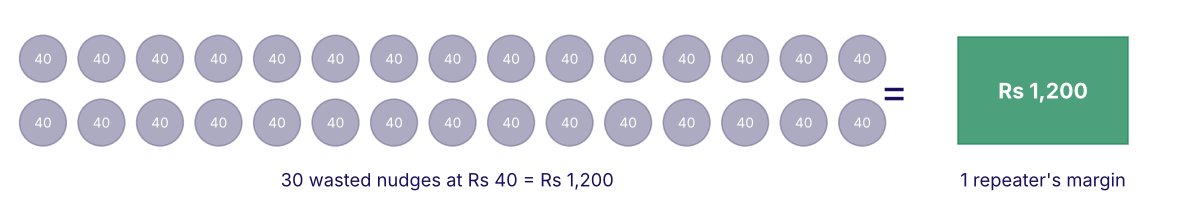

act when P(come back) is above 1 in 31 = 0.032


In [2]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for i in range(30):
    ax.add_patch(plt.Circle((i % 15 * 0.55 + 0.3, 0.95 - (i // 15) * 0.6), 0.22, color=MUTED, alpha=0.55))
    ax.text(i % 15 * 0.55 + 0.3, 0.95 - (i // 15) * 0.6, "40", ha="center", va="center", fontsize=9, color="white")
ax.text(4.1, -0.25, "30 wasted nudges at Rs 40 = Rs 1,200", ha="center", fontsize=12, color=INK)
ax.add_patch(plt.Rectangle((8.9, 0.15), 1.6, 1.0, color=GREEN, alpha=0.8))
ax.text(9.7, 0.65, "Rs 1,200", ha="center", va="center", fontsize=14, color="white", weight="bold")
ax.text(9.7, -0.25, "1 repeater's margin", ha="center", fontsize=12, color=INK)
ax.text(8.3, 0.65, "=", fontsize=28, ha="center", va="center", color=INK)
ax.set_xlim(0, 11); ax.set_ylim(-0.5, 1.4); ax.axis("off"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()
threshold = COST_WASTED / (COST_WASTED + COST_MISSED)
print(f"act when P(come back) is above 1 in {round(1 / threshold)} = {threshold:.3f}")

**What happened.** The answer is (c). Thirty wasted Rs 40 nudges cost what one repeater earns, so a nudge pays whenever the chance is above 1 in 31, which is 0.032. Written as a formula, named last: `threshold = cost of acting wrongly / (cost of acting wrongly + cost of failing to act) = 40 / 1,240`. The course calls it the 1-in-N test: rights per wrong equals damage over saving.

## Which metric leads in three businesses?

The same test, on three cost stories. Stripe's fraud guide works its own example: on a 26 dollar sale at 8 percent margin, a missed fraud costs 38.92 dollars and a false block loses 2.08 dollars of profit (Stripe, verified 28 October 2026). Rohan Desai's loans at Kalpa Financial Services cost Rs 60,000 for a false approval and Rs 3,000 for a wrongful rejection.

In [3]:
import pandas as pd
stories = pd.DataFrame([
    ["Kalpa nudge", "nudge", "P(buy)", 40, 1200],
    ["Stripe fraud block", "block", "P(fraud)", 2.08, 38.92],
    ["Kalpa Financial loan", "lend", "P(repay)", 60000, 3000],
], columns=["business", "action", "on", "cost of acting wrongly", "cost of failing to act"])
stories["act above"] = stories["cost of acting wrongly"] / (stories["cost of acting wrongly"] + stories["cost of failing to act"])
stories["leads"] = ["recall: a miss is the dear error", "recall of fraud: a missed fraud is dear", "precision: a false approval is dear"]
print(stories.to_string(index=False, formatters={"act above": "{:.3f}".format}))

            business action       on  cost of acting wrongly  cost of failing to act act above                                   leads
         Kalpa nudge  nudge   P(buy)                   40.00                 1200.00     0.032        recall: a miss is the dear error
  Stripe fraud block  block P(fraud)                    2.08                   38.92     0.051 recall of fraud: a missed fraud is dear
Kalpa Financial loan   lend P(repay)                60000.00                 3000.00     0.952     precision: a false approval is dear


## The trap: choosing the metric by habit

Three invented models score the twenty customers of chapter 1. All three are 75 percent accurate, so a team that picks by accuracy calls them equal. Anand's prices say they differ by Rs 5,800.

In [4]:
models = {"flags nobody": (0, 0, 5, 15), "chapter 1 model": (3, 3, 2, 12), "flags ten": (5, 5, 0, 10)}
for name, (tp, fp, fn, tn) in models.items():
    print(f"{name:<16} accuracy {(tp + tn) / 20:.0%}   bill Rs {fp * COST_WASTED + fn * COST_MISSED:>5,}")
accs = {(tp + tn) / 20 for tp, fp, fn, tn in models.values()}
bills = [fp * COST_WASTED + fn * COST_MISSED for tp, fp, fn, tn in models.values()]
print("PASS  all three tie on accuracy" if len(accs) == 1 else "CHECK accuracy")
print("PASS  the bills differ by Rs 5,800" if max(bills) - min(bills) == 5800 else "CHECK bills")
print("PASS  the nudge threshold is 1 in 31" if abs(threshold - 1 / 31) < 1e-12 else "CHECK threshold")

flags nobody     accuracy 75%   bill Rs 6,000
chapter 1 model  accuracy 75%   bill Rs 2,520
flags ten        accuracy 75%   bill Rs   200
PASS  all three tie on accuracy
PASS  the bills differ by Rs 5,800
PASS  the nudge threshold is 1 in 31


## A second route: rights per wrong

Count instead of dividing. Each wrong nudge does Rs 40 of damage and each right one saves Rs 1,200, so one right covers `1,200 / 40 = 30` wrongs, and the break-even group is one right in 31. For the loan, each wrong approval does Rs 60,000 of damage and each right one earns Rs 3,000, so it takes `60,000 / 3,000 = 20` rights to cover one wrong: lend only when at least 20 in 21 repay.

In [5]:
n_nudge = COST_MISSED / COST_WASTED + 1
n_loan = 60000 / 3000 + 1
print(f"nudge: act above 1 in {n_nudge:.0f} = {1 / n_nudge:.3f};  loan: lend above {n_loan - 1:.0f} in {n_loan:.0f} = {(n_loan - 1) / n_loan:.3f}")
print("PASS  the count agrees with the formula for the nudge" if abs(1 / n_nudge - threshold) < 1e-12 else "CHECK nudge")
print("PASS  the count agrees with the formula for the loan" if abs((n_loan - 1) / n_loan - 60000 / 63000) < 1e-12 else "CHECK loan")

nudge: act above 1 in 31 = 0.032;  loan: lend above 20 in 21 = 0.952
PASS  the count agrees with the formula for the nudge
PASS  the count agrees with the formula for the loan


## What did this chapter establish?

| Business | Cost of acting wrongly | Cost of failing to act | Act above | Metric that leads |
|---|---|---|---|---|
| Kalpa nudge | Rs 40 | Rs 1,200 | P(buy) 0.032 | recall |
| Stripe fraud block | 2.08 dollars | 38.92 dollars | P(fraud) 0.051 | recall of fraud |
| Kalpa Financial loan | Rs 60,000 | Rs 3,000 | P(repay) 0.952 | precision |

**The rule.** The metric follows the dearer mistake: when a miss costs more, recall leads and the threshold falls; when a false action costs more, precision leads and it rises. The formula assumes the model's probabilities are honest, so it is checked on the real scores in case 2.

**In the interview.** "How do you set a threshold when the two errors cost differently?" Price both, divide, say the threshold and which metric it protects.

Chapter 5 slides the threshold across a table of scores and watches the bill.